# Basic Ensembles

This notebook compares single models with voting, bagging, random forests, boosting, and stacking. The data is a small made-up moons dataset.


## Step 1 - Load the Data

Each row is one point with two coordinates, `x1` and `x2`. The label is 0 or 1. These coordinates have no units.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (VotingClassifier, BaggingClassifier,
                              RandomForestClassifier, AdaBoostClassifier,
                              HistGradientBoostingClassifier, StackingClassifier)
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

data = pd.read_csv("ensemble_moons_demo.csv")
features = ["x1", "x2"]
X = data[features]
y = data["class_label"]
print(data.shape, X.shape, y.shape)
print(data.head())


(500, 3) (500, 2) (500,)
         x1        x2  class_label
0  0.831039 -0.258749            1
1  1.185064  0.920387            0
2  1.164022 -0.455526            1
3 -0.023656  1.086288            0
4  0.480503  1.509424            0


The file has 500 rows. `X` has the two coordinates. `y` has the class label.

`class_label` cannot be included in `X`. It is the answer we are trying to predict. If it were included in `X`, the model would see the answer before it tried to learn from the coordinates.


## Step 2 - Reserve the Test Set

The split keeps 80% of the rows for development and 20% for a final test. The class mix stays about the same in both parts because the split is stratified.


In [2]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
assert X_dev.index.equals(y_dev.index)
assert X_test.index.equals(y_test.index)
assert set(X_dev.index).isdisjoint(X_test.index)
print(X_dev.shape, X_test.shape)


(400, 2) (100, 2)


This split makes 400 development rows and 100 test rows.

The test set stays hidden until Step 11. Plots, cross-validation, and model choices use only the development rows. Saving the test rows until the end keeps the last score an honest check.


## Step 3 - Explore Development Rows

These checks use only the development rows. `x1` and `x2` are unitless classroom coordinates.


x1             float64
x2             float64
class_label      int64
dtype: object
x1             0
x2             0
class_label    0
dtype: int64
           x1      x2  class_label
count  400.00  400.00        400.0
mean     0.49    0.26          0.5
std      0.91    0.61          0.5
min     -1.74   -1.25          0.0
25%     -0.13   -0.20          0.0
50%      0.44    0.27          0.5
75%      1.15    0.74          1.0
max      2.57    1.77          1.0
class_label
0    200
1    200
Name: count, dtype: int64
Majority rate: 0.5


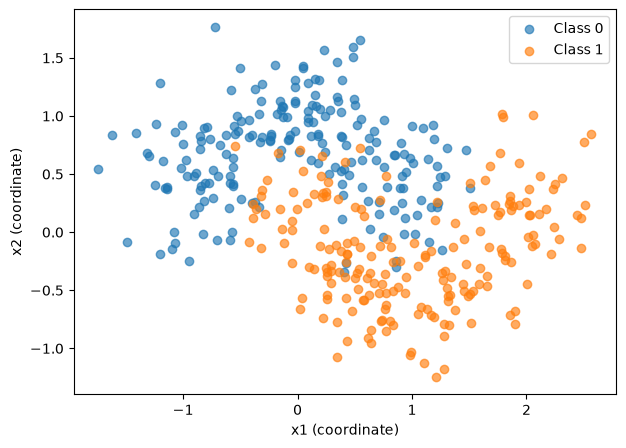

In [3]:
train = X_dev.copy()
train["class_label"] = y_dev
print(train.dtypes)
print(train.isna().sum())
print(train.describe().round(2))
print(y_dev.value_counts().sort_index())
print("Majority rate:", y_dev.value_counts(normalize=True).max())

plt.figure(figsize=(7, 5))
for label, group in train.groupby("class_label"):
    plt.scatter(group.x1, group.x2, label=f"Class {label}", alpha=0.65)
plt.xlabel("x1 (coordinate)")
plt.ylabel("x2 (coordinate)")
plt.legend()
plt.show()


There are no missing values. Both classes have 200 development rows, so the majority-class rate is 0.5.

The scatter plot shows two curved moon shapes. A straight boundary can have trouble separating them because the classes bend around each other.


## Step 4 - Baseline and Validation

The same 5 shuffled stratified folds will score every model. The dummy model always predicts the most common class. That baseline gives a simple score to compare the real models against.


In [4]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
def cv_accuracy(model):
    scores = cross_val_score(model, X_dev, y_dev, cv=folds, scoring="accuracy")
    return scores.mean(), scores.std()

baseline = DummyClassifier(strategy="most_frequent")
print("Dummy CV mean and spread:", cv_accuracy(baseline))


Dummy CV mean and spread: (np.float64(0.5), np.float64(0.0))


The dummy CV mean is 0.5 and the spread is 0. That matches the even class split.

The baseline is useful because an accuracy score needs a simple comparison. If 90% of the rows were one class, always guessing that class could score about 90%. The dummy score shows when a result is just the easy class balance.


## Step 5 - Compare Single Models

Logistic regression uses a straight boundary. A tree can split the space into boxy regions. A forest uses many trees.


In [5]:
single_models = {
    "logistic": LogisticRegression(max_iter=1000, random_state=42),
    "tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "forest": RandomForestClassifier(n_estimators=100, random_state=42),
}
for name, model in single_models.items():
    mean, spread = cv_accuracy(model)
    print(f"{name}: {mean:.3f} ± {spread:.3f}")


logistic: 0.842 ± 0.017


tree: 0.885 ± 0.024


forest: 0.905 ± 0.020


Logistic regression scored 0.842 ± 0.017. The tree scored 0.885 ± 0.024. The forest scored 0.905 ± 0.020.

All three are above the dummy score of 0.5. The forest mean is a little higher than the tree mean. The spreads still overlap, so a small difference in means does not prove a winner.


## Step 6 - Hard and Soft Voting

The voters are logistic regression, a random forest, and a calibrated support vector classifier.

Hard voting: the models vote for a class. The class with more votes wins.

Soft voting: the models combine their probability estimates.


In [6]:
voters = [
    ("lr", LogisticRegression(max_iter=1000, random_state=42)),
    ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
    ("svc", CalibratedClassifierCV(SVC(random_state=42), ensemble=False)),
]
hard_vote = VotingClassifier(estimators=voters, voting="hard")
soft_vote = VotingClassifier(estimators=voters, voting="soft")
for name, model in [("hard", hard_vote), ("soft", soft_vote)]:
    print(name, cv_accuracy(model))


hard (np.float64(0.9099999999999999), np.float64(0.012247448713915915))


soft (np.float64(0.9175000000000001), np.float64(0.018708286933869722))


Hard voting had a mean of about 0.910 and a spread of about 0.012. Soft voting had a mean of about 0.918 and a spread of about 0.019. Soft voting is a little higher. The gap is small beside the fold spread.

Voting can still fail when the models make the same mistakes. If all three are wrong on the same row, the vote is wrong too.


## Step 7 - Bagging and OOB

Bagging fits many trees on bootstrap samples. A bootstrap sample can repeat some rows and leave other rows out.


In [7]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100, max_samples=0.8, bootstrap=True,
    oob_score=True, random_state=42, n_jobs=-1)
bag.fit(X_dev, y_dev)
print("OOB accuracy:", round(bag.oob_score_, 3))
print("CV accuracy:", cv_accuracy(BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100, max_samples=0.8, bootstrap=True,
    random_state=42, n_jobs=-1)))


OOB accuracy: 0.895


CV accuracy: (np.float64(0.9099999999999999), np.float64(0.019999999999999997))


OOB accuracy was 0.895. CV accuracy had a mean of about 0.910 and a spread of about 0.020. These are two estimates, so they do not have to match.

OOB means out-of-bag. Rows that are left out of a tree's bootstrap sample can be used to check that tree.

OOB scoring is unavailable when `bootstrap=False`. That setting does not draw bootstrap samples, so there are no out-of-bag rows to score.


## Step 8 - Random Forest

A random forest bags trees and also looks at random feature subsets when it splits.


In [8]:
forest = RandomForestClassifier(
    n_estimators=100, max_features="sqrt", oob_score=True,
    random_state=42, n_jobs=-1)
forest.fit(X_dev, y_dev)
print("Forest OOB:", round(forest.oob_score_, 3))
print("Forest CV:", cv_accuracy(RandomForestClassifier(
    n_estimators=100, max_features="sqrt", random_state=42, n_jobs=-1)))
print(dict(zip(features, forest.feature_importances_.round(3))))


Forest OOB: 0.897


Forest CV: (np.float64(0.905), np.float64(0.020310096011589895))
{'x1': np.float64(0.435), 'x2': np.float64(0.565)}


Forest OOB was 0.897. Forest CV had a mean of about 0.905 and a spread of about 0.020.

The importances were about 0.435 for `x1` and 0.565 for `x2`. They add to about 1.

Feature importance tells us how much this fitted forest used a feature. It does not prove that the feature causes the class.


## Step 9 - Boosting

AdaBoost pays more attention to earlier mistakes. Histogram gradient boosting fits corrections step by step.


In [9]:
boost_models = {
    "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=0.5,
                                  random_state=42),
    "HistGB": HistGradientBoostingClassifier(max_iter=100,
                                             learning_rate=0.1,
                                             random_state=42),
}
for name, model in boost_models.items():
    print(name, cv_accuracy(model))


AdaBoost (np.float64(0.905), np.float64(0.015000000000000027))


HistGB (np.float64(0.9025000000000001), np.float64(0.031024184114977132))


AdaBoost had a mean of about 0.905 and a spread of about 0.015. HistGradientBoosting had a mean of about 0.902 and a spread of about 0.031.

Both are far above the dummy baseline of 0.5. Both are close to the forest CV mean of about 0.905. The histogram model has a wider spread.

Boosting builds learners in sequence, so later learners depend on earlier work. This makes it harder to parallelize than bagging. Bagged trees are separate, so they can be trained at the same time.


## Step 10 - Stacking

Stacking trains a last model on predictions from the other models. Those predictions come from held-out development folds.

The loop below is one controlled change. It compares the same random forest with 20 trees and with 100 trees.


In [10]:
stack = StackingClassifier(
    estimators=[("lr", LogisticRegression(max_iter=1000, random_state=42)),
                ("rf", RandomForestClassifier(n_estimators=100,
                                              random_state=42))],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5, n_jobs=-1)
print("Stack CV:", cv_accuracy(stack))

# Student change: compare 20 and 100 trees on development folds.
for count in (20, 100):
    candidate = RandomForestClassifier(n_estimators=count,
                                       random_state=42, n_jobs=-1)
    print(count, cv_accuracy(candidate))


Stack CV: (np.float64(0.9024999999999999), np.float64(0.02150581316760657))


20 (np.float64(0.8975), np.float64(0.01457737973711325))


100 (np.float64(0.905), np.float64(0.020310096011589895))


Stacking CV had a mean of about 0.902 and a spread of about 0.022.

The 20-tree forest had a mean of 0.8975 and a spread of about 0.015. The 100-tree forest had a mean of 0.905 and a spread of about 0.020. The 100-tree mean is a little higher. The difference is small next to the fold spread. More trees also take more computing time.


## Step 11 - Final Model and Test

I reviewed the development-fold results before using the test set.

**Model selected:** soft voting (`soft_vote`)

**Reason:** Soft voting had the highest development mean, about 0.918. Hard voting and bagging were next, both about 0.910. The gap is small beside the fold spread. Soft voting is still the strongest development result, so this is the frozen model.

The final test set should be used only once. This choice is already written down. After the test cell runs, the result gets reported as it is.


Final test accuracy: 0.91
Dummy test accuracy: 0.5


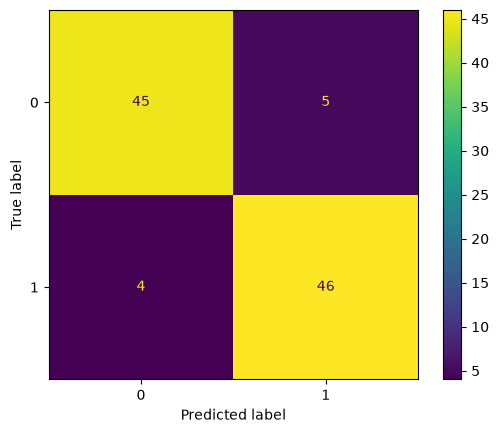

In [11]:
final_model = soft_vote
final_model.fit(X_dev, y_dev)
test_predictions = final_model.predict(X_test)
print("Final test accuracy:",
      round(accuracy_score(y_test, test_predictions), 3))
print("Dummy test accuracy:",
      round(DummyClassifier(strategy="most_frequent")
            .fit(X_dev, y_dev).score(X_test, y_test), 3))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions)
plt.show()


The final test accuracy is 0.91. The dummy test accuracy is 0.5.

The confusion matrix shows the correct and incorrect cases. 45 rows of class 0 were predicted as 0, and 46 rows of class 1 were predicted as 1. Those 91 cases are correct. 5 rows of class 0 were predicted as 1, and 4 rows of class 1 were predicted as 0. Those 9 cases are incorrect.

The test score of 0.91 is a little lower than the soft-voting development mean of about 0.918. The test rows are a different sample. The correct action is to report this result, not to retune the model.

This dataset is synthetic, made-up classroom data, so the test result does not prove how well the model would work in a real-world situation.
